## Addidas dataset analysis

In [5]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [6]:
#import dataset
df=pd.read_excel('adidass.xlsx',skiprows=4)

In [7]:
df.drop(columns='Unnamed: 0',inplace=True)

In [8]:
df

,Retailer,Retailer ID,Invoice Date,Region,State,City,Product,Price per Unit,Units Sold,Total Sales,Operating Profit,Sales Method
0,Foot Locker,1185732,43831,Northeast,New York,New York,Men's Street Footwear,50.0,1200,60000.0,30000.000,In-store
1,Foot Locker,1185732,43832,Northeast,New York,New York,Men's Athletic Footwear,50.0,1000,50000.0,15000.000,In-store
2,Foot Locker,1185732,43833,Northeast,New York,New York,Women's Street Footwear,40.0,1000,40000.0,14000.000,In-store
3,Foot Locker,1185732,43834,Northeast,New York,New York,Women's Athletic Footwear,45.0,850,38250.0,13387.500,In-store
4,Foot Locker,1185732,43835,Northeast,New York,New York,Men's Apparel,60.0,900,54000.0,16200.000,In-store
...,...,...,...,...,...,...,...,...,...,...,...,...
9643,Foot Locker,1185732,44220,Northeast,New Hampshire,Manchester,Men's Apparel,50.0,64,320.0,89.600,Outlet
9644,Foot Locker,1185732,44220,Northeast,New Hampshire,Manchester,Women's Apparel,41.0,105,430.5,137.760,Outlet
9645,Foot Locker,1185732,44249,Northeast,New Hampshire,Manchester,Men's Street Footwear,41.0,184,754.4,279.128,Outlet
9646,Foot Locker,1185732,44249,Northeast,New Hampshire,Manchester,Men's Athletic Footwear,42.0,70,294.0,123.480,Outlet


In [9]:

df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

Retailer            0
Retailer ID         0
Invoice Date        0
Region              7
State               0
City                0
Product             0
Price per Unit      2
Units Sold          0
Total Sales         0
Operating Profit    0
Sales Method        0
dtype: int64

In [11]:
df[df['Price per Unit'].isna()]

,Retailer,Retailer ID,Invoice Date,Region,State,City,Product,Price per Unit,Units Sold,Total Sales,Operating Profit,Sales Method
16,Foot Locker,1185732,43859,Northeast,New York,New York,Men's Apparel,NaN,850,51000.0,15300.0,Outlet
78,Sports Direct,1197831,44041,South,Texas,Houston,Men's Apparel,NaN,500,20000.0,6000.0,Outlet


In [12]:
non=df.groupby(['State','Region'])['Price per Unit'].transform('mean')

In [13]:
non

0       49.080780
1       49.080780
2       49.080780
3       49.080780
4       49.080780
          ...    
9643    53.638889
9644    53.638889
9645    53.638889
9646    53.638889
9647    53.638889
Name: Price per Unit, Length: 9648, dtype: float64

In [14]:
df['Price per Unit']=df['Price per Unit'].fillna(non)

In [15]:
df.isnull().sum()

Retailer            0
Retailer ID         0
Invoice Date        0
Region              7
State               0
City                0
Product             0
Price per Unit      0
Units Sold          0
Total Sales         0
Operating Profit    0
Sales Method        0
dtype: int64

In [16]:
df=df.dropna()

In [17]:
df.isnull().sum()

Retailer            0
Retailer ID         0
Invoice Date        0
Region              0
State               0
City                0
Product             0
Price per Unit      0
Units Sold          0
Total Sales         0
Operating Profit    0
Sales Method        0
dtype: int64

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9641 entries, 0 to 9647
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Retailer          9641 non-null   object 
 1   Retailer ID       9641 non-null   int64  
 2   Invoice Date      9641 non-null   int64  
 3   Region            9641 non-null   object 
 4   State             9641 non-null   object 
 5   City              9641 non-null   object 
 6   Product           9641 non-null   object 
 7   Price per Unit    9641 non-null   float64
 8   Units Sold        9641 non-null   int64  
 9   Total Sales       9641 non-null   float64
 10  Operating Profit  9641 non-null   float64
 11  Sales Method      9641 non-null   object 
dtypes: float64(3), int64(3), object(6)
memory usage: 979.2+ KB


In [19]:
df.groupby('Region')['Total Sales'].sum()

Region
Midwest      13560045.9
Northeast    18632406.7
South        14407693.1
Southeast    16317123.6
West         26902568.2
Name: Total Sales, dtype: float64

In [20]:
df.groupby('Product')['Operating Profit'].sum()/df['Operating Profit'].sum()*100

Product
Men's Apparel                13.391885
Men's Athletic Footwear      15.588957
Men's Street Footwear        24.972261
Men's aparel                  0.048857
Women's Apparel              20.679052
Women's Athletic Footwear    11.749847
Women's Street Footwear      13.569140
Name: Operating Profit, dtype: float64

In [21]:
df.iloc[:,6].unique()

array(["Men's Street Footwear", "Men's Athletic Footwear",
       "Women's Street Footwear", "Women's Athletic Footwear",
       "Men's Apparel", "Women's Apparel", "Men's aparel"], dtype=object)

In [22]:
df2=df.groupby('Product')['Operating Profit'].sum()

In [23]:
df2

Product
Men's Apparel                4440440.533
Men's Athletic Footwear      5168938.819
Men's Street Footwear        8280226.062
Men's aparel                   16200.000
Women's Apparel              6856697.056
Women's Athletic Footwear    3895978.494
Women's Street Footwear      4499213.931
Name: Operating Profit, dtype: float64

In [24]:
df2=pd.DataFrame(data=df2)

In [25]:
df2

,Operating Profit
Product,
Men's Apparel,4440440.533
Men's Athletic Footwear,5168938.819
Men's Street Footwear,8280226.062
Men's aparel,16200.000
Women's Apparel,6856697.056
Women's Athletic Footwear,3895978.494
Women's Street Footwear,4499213.931


In [26]:
df2['precenProfit']=df2['Operating Profit']/df2['Operating Profit'].sum()*100

In [27]:
df2

,Operating Profit,precenProfit
Product,,
Men's Apparel,4440440.533,13.391885
Men's Athletic Footwear,5168938.819,15.588957
Men's Street Footwear,8280226.062,24.972261
Men's aparel,16200.000,0.048857
Women's Apparel,6856697.056,20.679052
Women's Athletic Footwear,3895978.494,11.749847
Women's Street Footwear,4499213.931,13.569140


In [30]:
df

,Retailer,Retailer ID,Invoice Date,Region,State,City,Product,Price per Unit,Units Sold,Total Sales,Operating Profit,Sales Method,Day
0,Foot Locker,1185732,2020-01-01,Northeast,New York,New York,Men's Street Footwear,50.0,1200,60000.0,30000.000,In-store,Wednesday
1,Foot Locker,1185732,2020-01-02,Northeast,New York,New York,Men's Athletic Footwear,50.0,1000,50000.0,15000.000,In-store,Thursday
2,Foot Locker,1185732,2020-01-03,Northeast,New York,New York,Women's Street Footwear,40.0,1000,40000.0,14000.000,In-store,Friday
3,Foot Locker,1185732,2020-01-04,Northeast,New York,New York,Women's Athletic Footwear,45.0,850,38250.0,13387.500,In-store,Saturday
4,Foot Locker,1185732,2020-01-05,Northeast,New York,New York,Men's Apparel,60.0,900,54000.0,16200.000,In-store,Sunday
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9643,Foot Locker,1185732,2021-01-24,Northeast,New Hampshire,Manchester,Men's Apparel,50.0,64,320.0,89.600,Outlet,Sunday
9644,Foot Locker,1185732,2021-01-24,Northeast,New Hampshire,Manchester,Women's Apparel,41.0,105,430.5,137.760,Outlet,Sunday
9645,Foot Locker,1185732,2021-02-22,Northeast,New Hampshire,Manchester,Men's Street Footwear,41.0,184,754.4,279.128,Outlet,Monday
9646,Foot Locker,1185732,2021-02-22,Northeast,New Hampshire,Manchester,Men's Athletic Footwear,42.0,70,294.0,123.480,Outlet,Monday


In [31]:
df.groupby('Day')['Operating Profit'].mean()

Day
Friday       3811.790791
Monday       3341.073889
Saturday     3038.719017
Sunday       3191.792520
Thursday     3996.718972
Tuesday      3365.390975
Wednesday    3334.160878
Name: Operating Profit, dtype: float64

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9641 entries, 0 to 9647
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Retailer          9641 non-null   object        
 1   Retailer ID       9641 non-null   int64         
 2   Invoice Date      9641 non-null   datetime64[ns]
 3   Region            9641 non-null   object        
 4   State             9641 non-null   object        
 5   City              9641 non-null   object        
 6   Product           9641 non-null   object        
 7   Price per Unit    9641 non-null   float64       
 8   Units Sold        9641 non-null   int64         
 9   Total Sales       9641 non-null   float64       
 10  Operating Profit  9641 non-null   float64       
 11  Sales Method      9641 non-null   object        
 12  Day               9641 non-null   object        
dtypes: datetime64[ns](1), float64(3), int64(2), object(7)
memory usage: 1.0+ MB


In [33]:
df

,Retailer,Retailer ID,Invoice Date,Region,State,City,Product,Price per Unit,Units Sold,Total Sales,Operating Profit,Sales Method,Day
0,Foot Locker,1185732,2020-01-01,Northeast,New York,New York,Men's Street Footwear,50.0,1200,60000.0,30000.000,In-store,Wednesday
1,Foot Locker,1185732,2020-01-02,Northeast,New York,New York,Men's Athletic Footwear,50.0,1000,50000.0,15000.000,In-store,Thursday
2,Foot Locker,1185732,2020-01-03,Northeast,New York,New York,Women's Street Footwear,40.0,1000,40000.0,14000.000,In-store,Friday
3,Foot Locker,1185732,2020-01-04,Northeast,New York,New York,Women's Athletic Footwear,45.0,850,38250.0,13387.500,In-store,Saturday
4,Foot Locker,1185732,2020-01-05,Northeast,New York,New York,Men's Apparel,60.0,900,54000.0,16200.000,In-store,Sunday
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9643,Foot Locker,1185732,2021-01-24,Northeast,New Hampshire,Manchester,Men's Apparel,50.0,64,320.0,89.600,Outlet,Sunday
9644,Foot Locker,1185732,2021-01-24,Northeast,New Hampshire,Manchester,Women's Apparel,41.0,105,430.5,137.760,Outlet,Sunday
9645,Foot Locker,1185732,2021-02-22,Northeast,New Hampshire,Manchester,Men's Street Footwear,41.0,184,754.4,279.128,Outlet,Monday
9646,Foot Locker,1185732,2021-02-22,Northeast,New Hampshire,Manchester,Men's Athletic Footwear,42.0,70,294.0,123.480,Outlet,Monday


## Visualization

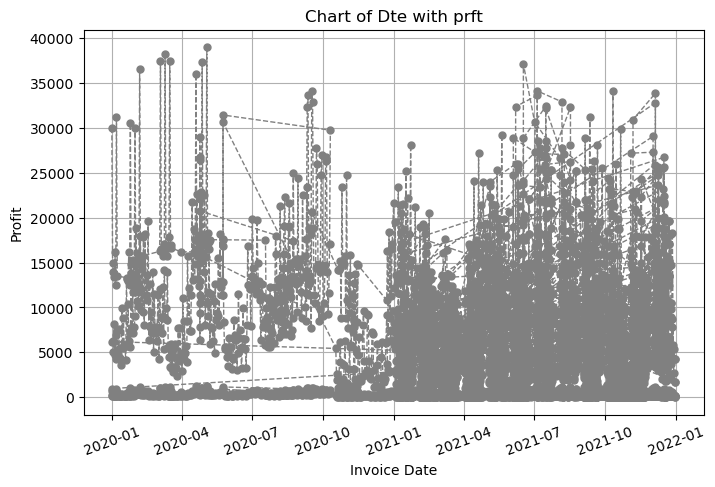

In [34]:
plt.figure(figsize=(8,5))
plt.plot(df['Invoice Date'],df['Operating Profit'],lw=1,c='gray',ls='--',marker='.',markersize=10)
plt.xticks(rotation=20)
plt.xlabel('Invoice Date')
plt.ylabel('Profit')
plt.title('Chart of Dte with prft')
plt.grid()
plt.show()

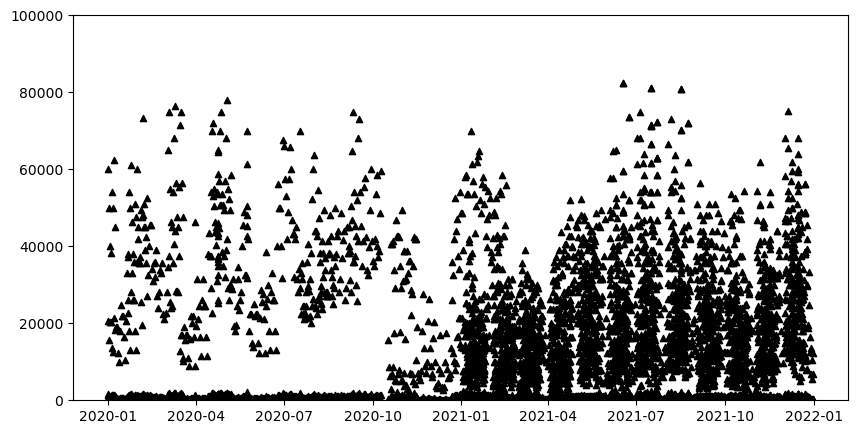

In [35]:
plt.figure(figsize=(10,5))
plt.scatter(df['Invoice Date'],df['Total Sales'],c='black',s=20,marker='^')
plt.ylim(0,100000)
plt.show()

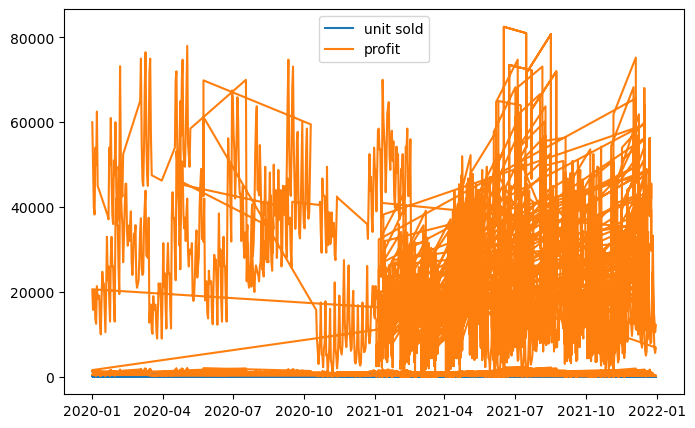

In [36]:
plt.figure(figsize=(8,5))
plt.plot(df['Invoice Date'],df['Units Sold'],label='unit sold')
plt.plot(df['Invoice Date'],df['Total Sales'],label='profit')
plt.legend(loc=0)
plt.show()

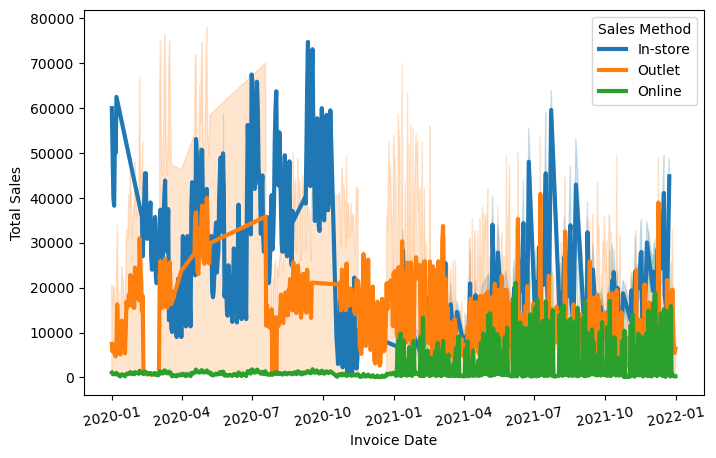

In [37]:
plt.figure(figsize=(8,5))
sns.lineplot(data=df,x='Invoice Date',y='Total Sales',lw=3,c='gray',hue='Sales Method')
plt.xticks(rotation=10)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

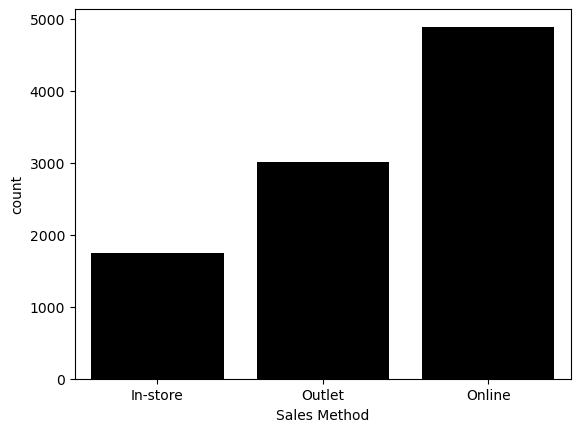

In [38]:
sns.countplot(data=df,x='Sales Method',color='black')
plt.show

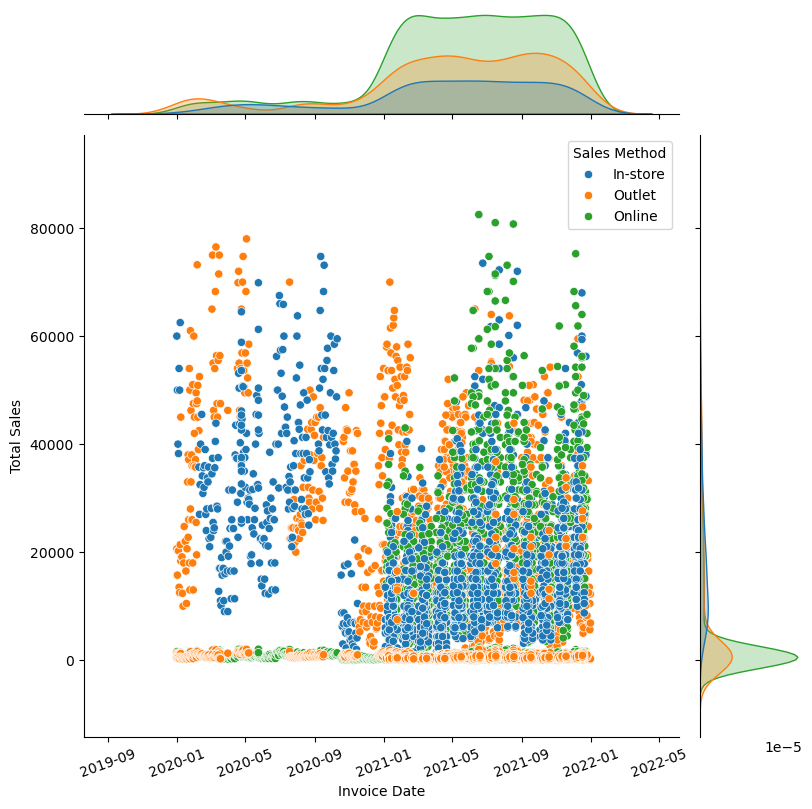

In [39]:
sns.jointplot(data=df,x='Invoice Date',y='Total Sales',height=8,hue='Sales Method')
plt.xticks(rotation=20)
plt.show()

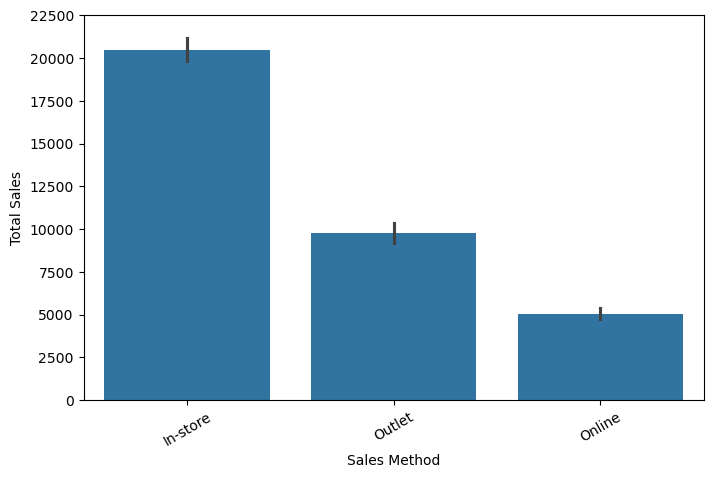

In [40]:
plt.figure(figsize=(8,5))
sns.barplot(data=df,x='Sales Method',y='Total Sales')
plt.xticks(rotation=30)
plt.ylim(0,22500)
plt.show()

In [41]:
px.bar(df,x='Product',y='Operating Profit',color='Sales Method',animation_frame='City',hover_name='Price per Unit')


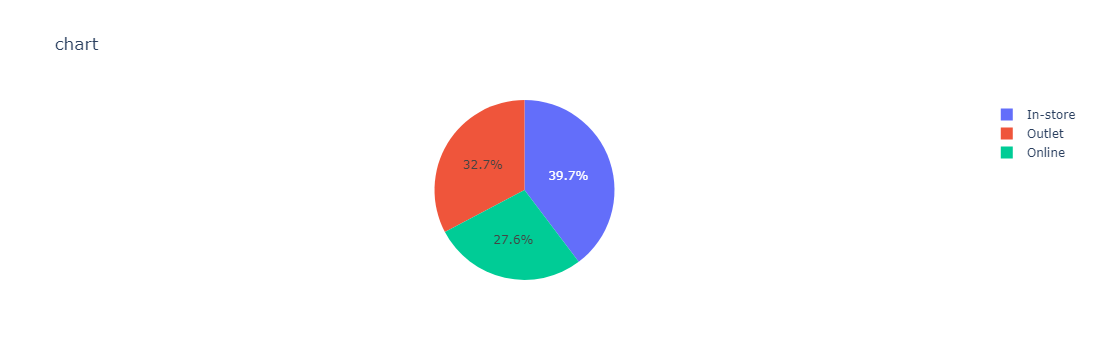

In [42]:
px.pie(df,values='Total Sales',names='Sales Method',title='chart',hover_name='Region')

In [43]:
px.sunburst(df,values='Total Sales',path=['State','Region'])

In [44]:
px.scatter_3d(df,x='Product',y='Operating Profit',z='Units Sold')

In [45]:
px.scatter_geo(
    df,
    locations='Region',
    locationmode='country names',
    color='Total Sales'
)

C:\Users\Softlaptop\AppData\Local\Temp\ipykernel_12064\447025335.py:1: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



In [46]:
from pivottablejs import pivot_ui as pu

In [47]:
pivot_ui(df)

In [48]:
df

,Retailer,Retailer ID,Invoice Date,Region,State,City,Product,Price per Unit,Units Sold,Total Sales,Operating Profit,Sales Method,Day
0,Foot Locker,1185732,2020-01-01,Northeast,New York,New York,Men's Street Footwear,50.0,1200,60000.0,30000.000,In-store,Wednesday
1,Foot Locker,1185732,2020-01-02,Northeast,New York,New York,Men's Athletic Footwear,50.0,1000,50000.0,15000.000,In-store,Thursday
2,Foot Locker,1185732,2020-01-03,Northeast,New York,New York,Women's Street Footwear,40.0,1000,40000.0,14000.000,In-store,Friday
3,Foot Locker,1185732,2020-01-04,Northeast,New York,New York,Women's Athletic Footwear,45.0,850,38250.0,13387.500,In-store,Saturday
4,Foot Locker,1185732,2020-01-05,Northeast,New York,New York,Men's Apparel,60.0,900,54000.0,16200.000,In-store,Sunday
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9643,Foot Locker,1185732,2021-01-24,Northeast,New Hampshire,Manchester,Men's Apparel,50.0,64,320.0,89.600,Outlet,Sunday
9644,Foot Locker,1185732,2021-01-24,Northeast,New Hampshire,Manchester,Women's Apparel,41.0,105,430.5,137.760,Outlet,Sunday
9645,Foot Locker,1185732,2021-02-22,Northeast,New Hampshire,Manchester,Men's Street Footwear,41.0,184,754.4,279.128,Outlet,Monday
9646,Foot Locker,1185732,2021-02-22,Northeast,New Hampshire,Manchester,Men's Athletic Footwear,42.0,70,294.0,123.480,Outlet,Monday
